# ViGoEmotions — Baseline và đánh giá midterm
TF-IDF + OvR Logistic Regression. Chỉ đánh giá validation; test giữ cho Final. GRU/PhoBERT chạy trong notebook 04 trên Colab.

## Kiểm tra môi trường
Chọn kernel **Python (ViGoEmotions)** (`ViGoEmotions/.venv/bin/python`), rồi **Restart Kernel → Run All**. Cell dưới kiểm tra dependency trước khi xử lý dữ liệu.

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd() if (Path.cwd() / "scripts").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT / "scripts"))
from check_environment import check_environment
check_environment()

Python kernel: /Users/mac/Documents/Studyspace/2026-2027/Semester_1/ATI/ViGoEmotions/.venv/bin/python
numpy: 2.5.4
scipy: 1.18.1
scikit-learn: 1.9.1


NumPy / SciPy / scikit-learn imports: OK


In [2]:
from pathlib import Path
import sys
ROOT = Path.cwd() if (Path.cwd() / 'scripts').exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT / 'scripts'))
import pandas as pd
from IPython.display import display, Image


In [3]:
from train_tfidf import main
main()

   model split  threshold  macro_f1  micro_f1  hamming_loss     lrap  parameter_count  train_seconds
tfidf_lr   val        0.5  0.238825  0.271238      0.060593 0.640745           940626       3.293814


## Bảng kết quả thật
Đọc thêm kết quả neural nếu notebook Colab đã sinh file. Không thay giá trị thiếu bằng 0.

In [4]:
files = sorted((ROOT/'reports/tables').glob('*_metrics.csv'))
display(pd.concat([pd.read_csv(p) for p in files], ignore_index=True))
display(pd.read_csv(ROOT/'reports/tables/tfidf_lr_per_label.csv'))

,model,split,threshold,macro_f1,micro_f1,hamming_loss,lrap,parameter_count,train_seconds
0,tfidf_lr,val,0.5,0.238825,0.271238,0.060593,0.640745,940626,3.293814


,model,split,label,train_count,support,precision,recall,f1
0,tfidf_lr,val,amusement,2868,327,0.714286,0.122324,0.208877
1,tfidf_lr,val,excitement,824,91,0.666667,0.021978,0.042553
2,tfidf_lr,val,joy,1614,168,0.833333,0.148810,0.252525
3,tfidf_lr,val,love,1175,148,0.818182,0.182432,0.298343
4,tfidf_lr,val,desire,762,102,0.600000,0.029412,0.056075
5,tfidf_lr,val,optimism,1046,122,0.862069,0.204918,0.331126
6,tfidf_lr,val,caring,1062,131,0.875000,0.213740,0.343558
7,tfidf_lr,val,pride,774,87,1.000000,0.379310,0.550000
8,tfidf_lr,val,admiration,883,107,1.000000,0.084112,0.155172
9,tfidf_lr,val,gratitude,765,96,0.912281,0.541667,0.679739


## Độ nhạy ngưỡng — chỉ validation
Ngưỡng tốt nhất trên validation không phải ước lượng không thiên lệch của test.

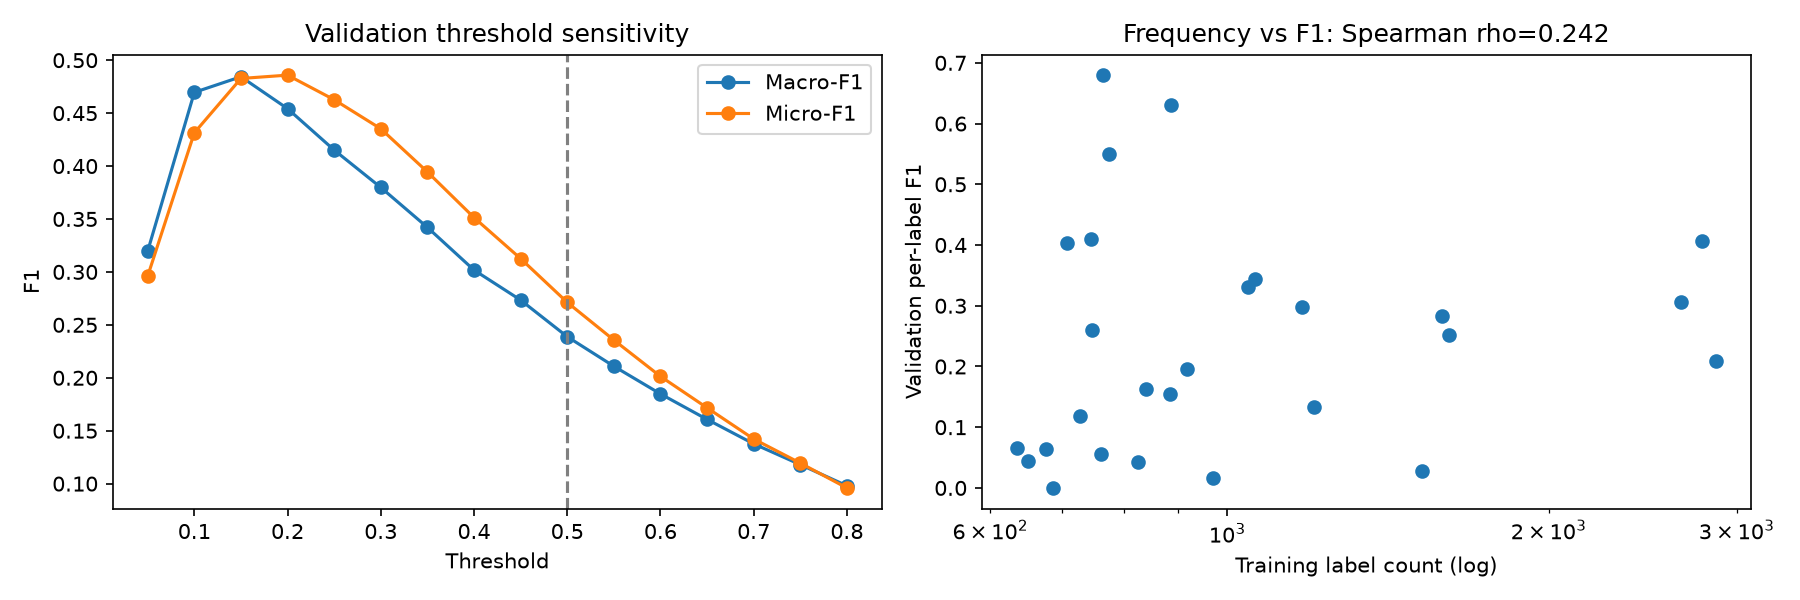

,threshold,macro_f1,micro_f1,hamming_loss,lrap
0,0.05,0.319722,0.296102,0.298483,0.640745
1,0.10,0.469602,0.431394,0.132086,0.640745
2,0.15,0.484370,0.482722,0.086677,0.640745
3,0.20,0.454230,0.485874,0.069162,0.640745
4,0.25,0.415119,0.462661,0.062045,0.640745
5,0.30,0.379806,0.435233,0.058621,0.640745
6,0.35,0.342088,0.394466,0.058065,0.640745
7,0.40,0.301759,0.351351,0.058513,0.640745
8,0.45,0.273401,0.312578,0.059374,0.640745
9,0.50,0.238825,0.271238,0.060593,0.640745


In [5]:
display(Image(filename=str(ROOT/'reports/figures/tfidf_lr_diagnostics.png')))
display(pd.read_csv(ROOT/'reports/tables/tfidf_lr_thresholds_val.csv'))

## Phân tích lỗi và phụ thuộc nhãn
20 FN và 20 FP được chọn theo mức tự tin sai; không phải mẫu lỗi ngẫu nhiên. Không xuất comment thô.

In [6]:
display(pd.read_csv(ROOT/'reports/tables/tfidf_lr_pair_preservation_val.csv'))
display(pd.read_csv(ROOT/'reports/tables/tfidf_lr_styles.csv'))
display(pd.read_csv(ROOT/'reports/tables/tfidf_lr_cardinality_val.csv'))
display(pd.read_csv(ROOT/'reports/tables/tfidf_lr_error_cases_val.csv'))

,label_a,label_b,train_count,val_true_count,val_pred_count,joint_true_positive,joint_recall
0,disappointment,sadness,904,122,2,2,0.016393
1,anger,annoyance,699,77,26,6,0.077922
2,sadness,grief,620,81,18,15,0.185185
3,amusement,joy,568,48,5,1,0.020833
4,annoyance,disapproval,469,67,2,1,0.014925
5,joy,love,395,50,9,6,0.120000
6,disgust,anger,379,49,12,8,0.163265
7,embarrassment,sadness,366,48,28,20,0.416667
8,excitement,joy,359,34,2,1,0.029412
9,disappointment,annoyance,336,41,1,0,0.000000


,model,split,style,n,macro_f1,micro_f1,hamming_loss,lrap
0,tfidf_lr,val,all,2066,0.238825,0.271238,0.060593,0.640745
1,tfidf_lr,val,short_le_5,343,0.331008,0.405028,0.045999,0.675440
2,tfidf_lr,val,emoji_heavy_ge_2,199,0.169002,0.193833,0.068118,0.583902
3,tfidf_lr,val,teencode,726,0.181872,0.247140,0.067136,0.628286


,cardinality,n,macro_f1,micro_f1,hamming_loss,lrap
0,0,75,0.000000,0.000000,0.001975,1.000000
1,1,622,0.254300,0.340686,0.032035,0.597248
2,2,927,0.245934,0.284177,0.063806,0.640097
3,3,387,0.172960,0.215524,0.099627,0.628283
4,>=4,55,0.169471,0.230769,0.134680,0.741357


,kind,sample_id,label,probability,true_labels,predicted_labels,cardinality,styles
0,FN,3069,pride,0.011811,joy;love;pride;admiration,amusement;joy;love,4,short_le_5
1,FN,4712,approval,0.012883,admiration;approval,NaN,2,NaN
2,FN,1930,realization,0.014017,realization,NaN,1,NaN
3,FN,2159,caring,0.014736,amusement;caring,NaN,2,NaN
4,FN,tik011933,amusement,0.015252,amusement;remorse,remorse,2,short_le_5
5,FN,23402,embarrassment,0.015820,embarrassment,NaN,1,teencode
6,FN,20457,fear,0.016276,fear;nervousness,NaN,2,NaN
7,FN,5454,nervousness,0.016757,fear;nervousness;annoyance,NaN,3,NaN
8,FN,6515,surprise,0.016835,amusement;surprise,NaN,2,emoji_heavy_ge_2
9,FN,3256,fear,0.016985,fear;nervousness,NaN,2,NaN


## RQ Final
Giữ nguyên backbone neural tốt nhất; so sánh ngưỡng 0.5, global tuned, per-label tuned. Tune trên validation, khóa ngưỡng và chỉ đánh giá test một lần. Xem README và báo cáo để biết giới hạn hiện tại.